# 📊 Task 2 — Step 2: Multimodal Data Preparation & Curriculum Splits
**Course:** EE-5102 / CS-6304: Advanced Topics in Machine Learning (Fall 2026, LUMS)  
**Datasets:** COCO 2014 Captions, COCO Instance Annotations, VQAv2 Complementary Pairs  
**Deterministic Global Seed:** `6304`

---

## 1. The Three Multimodal Data Components

The manual prescribes three data components structured into a strict curriculum:

1. **COCO Captions:**
   - Training: 6,000 images $\times$ 3 captions = 18,000 examples (drawn from `train2014`).
   - Development: 96 images with 1 caption each (drawn from `val2014`).
2. **Annotation-Derived Grounding (Presence & Counting):**
   - Generated programmatically from COCO instance annotations.
   - *Presence Template:* "Does this image contain [object]?" $\rightarrow$ paired with an image lacking the category (`yes`/`no`).
   - *Counting Template:* "How many [objects] can you see?" $\rightarrow$ paired with an image with a different count ($1 \le c \le 4$).
   - Development: 24 pairs (48 questions, 12 presence + 12 counting).
   - Final Test: 72 pairs (144 questions, 36 presence + 36 counting).
3. **Natural VQAv2 Complementary Pairs:**
   - Complementary image pairs sharing the exact same question string but possessing distinct reference answers.
   - Filtered for high annotator agreement: consensus answer must be agreed upon by at least **8 of 10 human annotators** for each image.
   - Development: 32 pairs (64 questions).
   - Final Test: 96 pairs (192 questions).
   - All evaluation sets are strictly image-disjoint from training and from one another.


In [1]:
import os, sys
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..', '..')))

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

from shared.src.seed import set_seed, SEED
from shared.src.plotting import set_style
from task2_vlm_grounding.src.data import normalize_vqa_answer, generate_presence_pair, generate_counting_pair

set_seed(6304)
set_style()

# Load curated Seed 6304 split manifest
with open("../splits/splits_seed6304.json", "r", encoding="utf-8") as f:
    splits_data = json.load(f)

print(f"Loaded Task 2 Split Manifest (Seed {splits_data['seed']}):")
for k, v in splits_data.items():
    if isinstance(v, dict):
        print(f" - {k}: {list(v.keys())}")


[Seed] Fixed random seed to 6304 (deterministic=True)
Loaded Task 2 Split Manifest (Seed 6304):
 - coco_captions: ['train_images', 'dev_images']
 - annotation_grounding: ['dev_pairs', 'test_pairs']
 - natural_vqav2: ['train_pairs', 'dev_pairs', 'test_pairs']


## 2. Programmatic Question Generation & Normalization Verification
We verify the programmatic generation of presence and counting pairs, and test VQAv2 consensus normalization.


In [2]:
# Test programmatic question generators
pair_presence = generate_presence_pair("bicycle", "COCO_val2014_000000123456", "COCO_val2014_000000654321")
pair_counting = generate_counting_pair("sheep", "COCO_val2014_000000111111", 2, "COCO_val2014_000000222222", 4)

print("Sample Presence Pair:")
print("  Question:", pair_presence["question"])
print(f"  Img A ({pair_presence['image_a']['image_id']}): {pair_presence['image_a']['target']}")
print(f"  Img B ({pair_presence['image_b']['image_id']}): {pair_presence['image_b']['target']}")

print("\nSample Counting Pair:")
print("  Question:", pair_counting["question"])
print(f"  Img A ({pair_counting['image_a']['image_id']}): {pair_counting['image_a']['target']}")
print(f"  Img B ({pair_counting['image_b']['image_id']}): {pair_counting['image_b']['target']}")

# Verify VQA Answer Normalization
raw_examples = ["A white dog", "two", "YES!", "3 cats.", "The blue car"]
norm_examples = [normalize_vqa_answer(x) for x in raw_examples]
df_norm = pd.DataFrame({"Raw String": raw_examples, "Normalized Target": norm_examples})
display(df_norm)


Sample Presence Pair:
  Question: Does this image contain bicycle?
  Img A (COCO_val2014_000000123456): yes
  Img B (COCO_val2014_000000654321): no

Sample Counting Pair:
  Question: How many sheeps can you see?
  Img A (COCO_val2014_000000111111): 2
  Img B (COCO_val2014_000000222222): 4


,Raw String,Normalized Target
0,A white dog,white dog
1,two,2
2,YES!,yes
3,3 cats.,3 cats
4,The blue car,blue car


## 3. Curriculum Mixture Probabilities & Split Summary
The manual specifies the sampling mixture across stages to prevent catastrophic forgetting through replay:
- **Stage 1 (2,250 updates):** 100% COCO Captions (connector alignment).
- **Stage 2 (1,500 updates):** 50% Presence pairs, 25% Counting pairs, 25% Caption replay.
- **Stage 3 (750 updates):** 70% Natural VQAv2, 10% Presence replay, 10% Counting replay, 10% Caption replay.


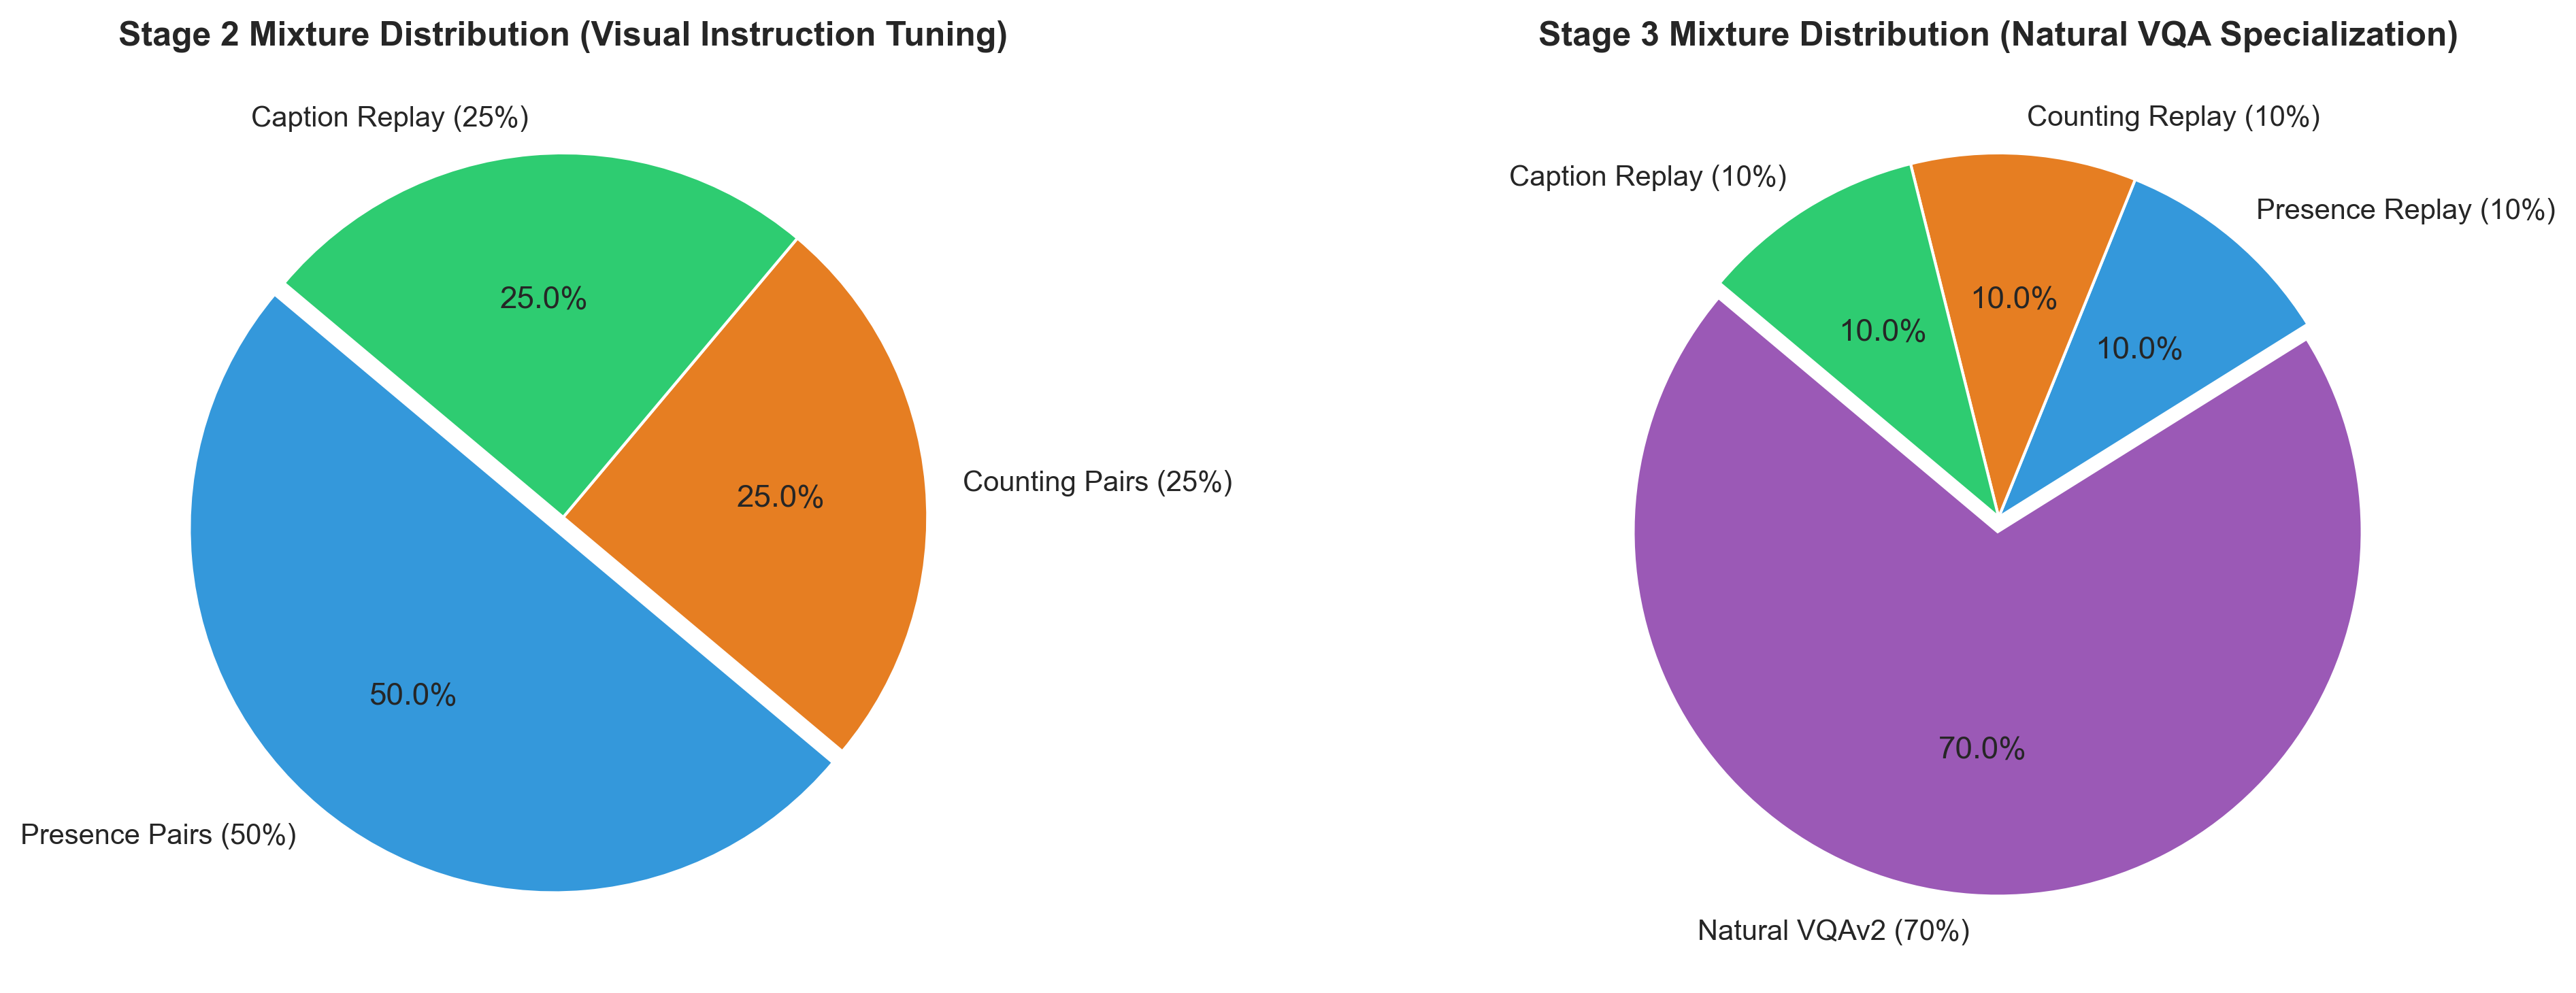

Saved curriculum sampling distribution figure.


In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.0))

# Stage 2 Sampling Distribution
labels_s2 = ["Presence Pairs (50%)", "Counting Pairs (25%)", "Caption Replay (25%)"]
sizes_s2 = [50, 25, 25]
colors_s2 = ["#3498DB", "#E67E22", "#2ECC71"]
ax1.pie(sizes_s2, labels=labels_s2, autopct='%1.1f%%', startangle=140, colors=colors_s2, explode=(0.04, 0, 0))
ax1.set_title("Stage 2 Mixture Distribution (Visual Instruction Tuning)", fontsize=12, fontweight="bold")

# Stage 3 Sampling Distribution
labels_s3 = ["Natural VQAv2 (70%)", "Presence Replay (10%)", "Counting Replay (10%)", "Caption Replay (10%)"]
sizes_s3 = [70, 10, 10, 10]
colors_s3 = ["#9B59B6", "#3498DB", "#E67E22", "#2ECC71"]
ax2.pie(sizes_s3, labels=labels_s3, autopct='%1.1f%%', startangle=140, colors=colors_s3, explode=(0.04, 0, 0, 0))
ax2.set_title("Stage 3 Mixture Distribution (Natural VQA Specialization)", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.savefig("../results/figures/task2_curriculum_sampling_proportions.png", dpi=300)
plt.show()
print("Saved curriculum sampling distribution figure.")
